# Estruturação

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
#Configuração básica de gráficos (visual executivo):

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (18,7
)

2.0 #Carga dos Datasets

In [4]:

orders = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_orders_dataset.csv", parse_dates=["order_purchase_timestamp"])
order_items = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_order_items_dataset.csv")
payments = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_order_payments_dataset.csv")
products = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_products_dataset.csv")
customers = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_customers_dataset.csv")
sellers = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_sellers_dataset.csv")
categories = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\product_category_name_translation.csv")
geolocations = pd.read_csv(r"C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset bruto\olist_geolocation_dataset.csv")


#criar uma view com base em clientes, para analaise por VTL.



2.1 #Somente Orders com status Delivered

In [161]:
orders_delivered = orders[orders["order_status"] == "delivered"]

In [162]:
orders_delivered

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00


3.0 Dataset analitico (Base master)

In [163]:
order_items.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')

In [164]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [165]:
customers.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='str')

In [166]:
# tabela_fato = orders.merge(
#     customers['customer_state'],
#     how='left',
#     on = customers['customer_id']
# )

# tabela_fato['order_id'] = tabela_fato['order_id'].astype(str)
# order_items['order_id'] = order_items['order_id'].astype(str) 

# tabela_fato = tabela_fato.merge(
#     order_items[['order_id','product_id']],
#     how='left',
#     on='order_id'
# )
# tabela_fato



## FASE#1
Seguindo a sugestão do Joao:
Fazendo as funções de MERGE em etapas.

## Orders + Order Items

1. Dataset Orders
2. Dataset Order_items
3. how == considerando todos os registros da Df do lado esquerdo
4. on == campo chave entre os Datasets.

5. como resultado: o novo df trouxe a coluna 'order_item_id','product_id', 'seller_id', 'price', 'freght_value'


Tabelas para adicionar:

order_items → valores e produto
products → categoria
customers → cliente / UF
sellers → seller / UF

In [167]:
df = (
   orders.merge(
        order_items[['order_id','order_item_id','product_id','seller_id','price','freight_value']],
        how='left',
        on='order_id'
       
   )

)

In [168]:
df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value'],
      dtype='str')

## FASE#2

## Enriquecer com Produtos (categoria)

Adicionado ao Df a coluna 'product_category_name', considerando como chave a coluna 'product_id'.

In [169]:
df = df.merge(
    products[['product_id','product_category_name']],
    how='left',
    on='product_id'
    
)

In [170]:
df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value',
       'product_category_name'],
      dtype='str')

## Fase#3

## Enriquecer com Sellers (UF/Seller)

Adicionado ao Df a coluna 'seller_state', considerando como chave a coluna 'seller_id'.

In [171]:
df = df.merge(
    sellers[['seller_id','seller_state']],
    how='left',
    on='seller_id'
)

In [172]:
df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value',
       'product_category_name', 'seller_state'],
      dtype='str')

## Resultado

### Chaves
1. order_id
2. order_item_id
3. product_id
4. seller_id
5. customer_unique_id

### Financeiro
6. price
7. freight_value
8. revenue_item = price + freight_value (A SER CRIADO AINDA)

### Dimensão
9. product_category_name
10. customer_name
11. seller_state
12. order_purchase_timestamp

sugestão refazer o merge nesse formato:

df.orders + orders_items

resultado + produtos

resultado + clientes

resultados + seller

In [173]:
#df = (
 #   orders_delivered
 #   .merge(order_items, on="order_id")
 #.merge(products, on="product_id", how="left")
 # .merge(customers, on="customer_id", how="left")
 #  .merge(sellers, on="seller_id", how="left")
 #   
#)


# df original + produtos
# resultado + items
# re

In [174]:
df.shape

(113425, 15)

verificando colunas existente

In [175]:
#Para pegar o nome das colunas do dataset e colchetes para selecionar a coluna o trazer uma determinada quantidade de colunas.
df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value',
       'product_category_name', 'seller_state'],
      dtype='str')

In [176]:
#df.columns[:7] #seleciona as 7 primeiras colunas do dataset


In [177]:
df

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,price,freight_value,product_category_name,seller_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,29.99,8.72,utilidades_domesticas,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1.0,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,118.70,22.76,perfumaria,SP
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1.0,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,159.90,19.22,automotivo,SP
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1.0,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,45.00,27.20,pet_shop,MG
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1.0,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,19.90,8.72,papelaria,SP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113420,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,1.0,f1d4ce8c6dd66c47bbaa8c6781c2a923,1f9ab4708f3056ede07124aad39a2554,174.90,20.10,bebes,SP
113421,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,1.0,b80910977a37536adeddd63663f916ad,d50d79cb34e38265a8649c383dcffd48,205.99,65.02,eletrodomesticos_2,SP
113422,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,1.0,d1c427060a0f73f6b889a5c7c61f2ac4,a1043bafd471dff536d0c462352beb48,179.99,40.59,informatica_acessorios,MG
113423,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,2.0,d1c427060a0f73f6b889a5c7c61f2ac4,a1043bafd471dff536d0c462352beb48,179.99,40.59,informatica_acessorios,MG


# 1.0 - Receita (Anual e Mensal) Fato vs Dimensão

In [179]:
###Receita total por pedido (revenue) é calculada somando o valor do produto (price) e o valor do frete (freight_value) para cada item do pedido.
df["revenue"] = df["price"] + df["freight_value"]
df["year"] = df["order_purchase_timestamp"].dt.year
#df["month"] = df["order_purchase_timestamp"].dt.to_period("M")
df["month"] = pd.to_datetime(df["order_purchase_timestamp"]).dt.to_period("M")

In [180]:
df

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,price,freight_value,product_category_name,seller_state,revenue,year,month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,29.99,8.72,utilidades_domesticas,SP,38.71,2017,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1.0,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,118.70,22.76,perfumaria,SP,141.46,2018,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1.0,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,159.90,19.22,automotivo,SP,179.12,2018,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1.0,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,45.00,27.20,pet_shop,MG,72.20,2017,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1.0,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,19.90,8.72,papelaria,SP,28.62,2018,2018-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113420,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,1.0,f1d4ce8c6dd66c47bbaa8c6781c2a923,1f9ab4708f3056ede07124aad39a2554,174.90,20.10,bebes,SP,195.00,2018,2018-02
113421,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,1.0,b80910977a37536adeddd63663f916ad,d50d79cb34e38265a8649c383dcffd48,205.99,65.02,eletrodomesticos_2,SP,271.01,2017,2017-08
113422,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,1.0,d1c427060a0f73f6b889a5c7c61f2ac4,a1043bafd471dff536d0c462352beb48,179.99,40.59,informatica_acessorios,MG,220.58,2018,2018-01
113423,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,2.0,d1c427060a0f73f6b889a5c7c61f2ac4,a1043bafd471dff536d0c462352beb48,179.99,40.59,informatica_acessorios,MG,220.58,2018,2018-01


# 2.0 Visão executiva - Qtd. Orders/Years

In [181]:
from matplotlib.ticker import MultipleLocator

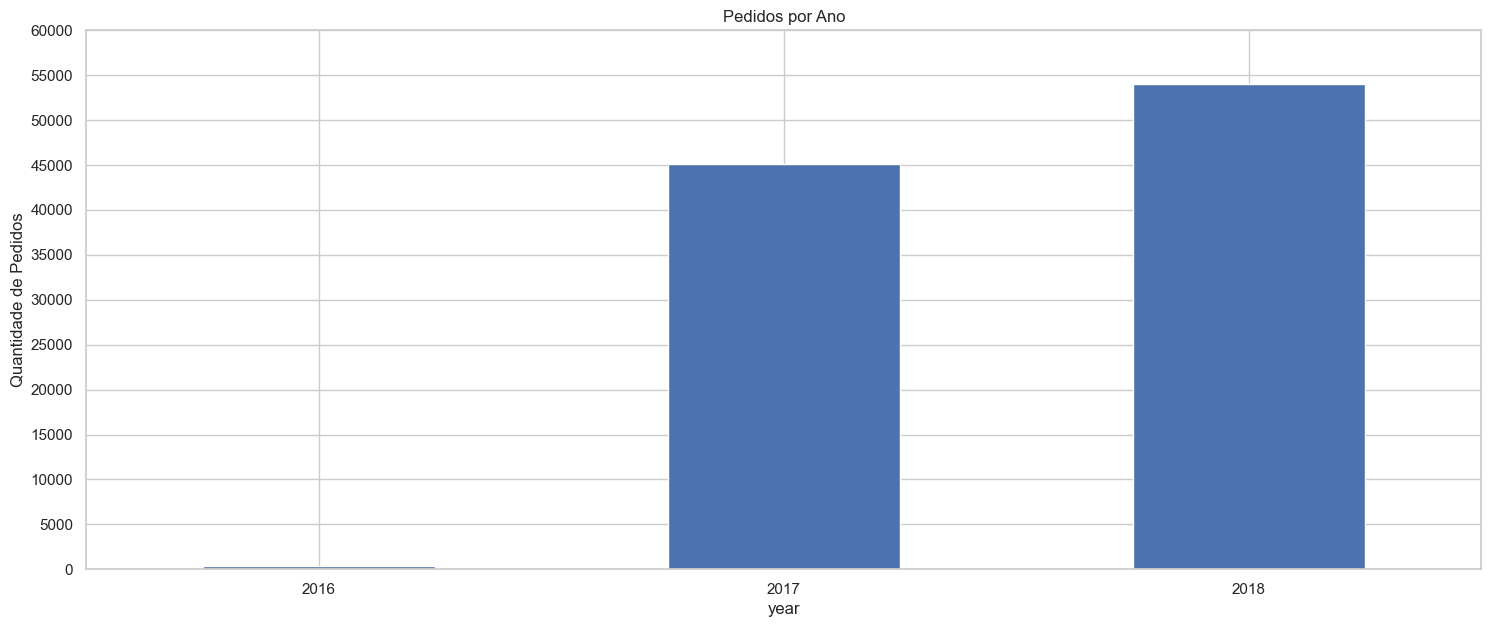

In [187]:

orders_per_year = df.groupby("year")["order_id"].nunique()

axis = orders_per_year.plot(kind="bar", title="Pedidos por Ano")
#axis = plt.ylabel("Quantidade de Pedidos")
#axis = plt.xticks(rotation=0)
#axis = plt.ylim(0,60000)

#axis = plt.show()


axis.set_ylabel("Quantidade de Pedidos")
axis.set_xticklabels(axis.get_xticklabels(), rotation=0)
axis.set_ylim(0, 60000)

# ✅ intervalo do eixo Y
axis.yaxis.set_major_locator(MultipleLocator(5000))

plt.show()


# 2.1 Visão executiva - Qtd. Orders/Years

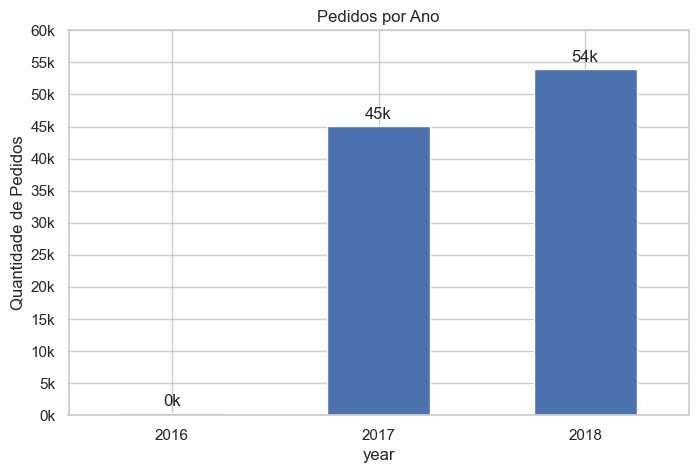

In [183]:

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter

orders_per_year = df.groupby("year")["order_id"].nunique()

fig, ax = plt.subplots(figsize=(8, 5))

orders_per_year.plot(kind="bar", ax=ax, title="Pedidos por Ano")

# Labels e limites
ax.set_ylabel("Quantidade de Pedidos")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_ylim(0, 60000)

# Intervalo do eixo Y
ax.yaxis.set_major_locator(MultipleLocator(5000))

# ✅ Formatter único (FONTE DA VERDADE)
formatter = FuncFormatter(lambda x, _: f"{int(x/1000)}k")

# ✅ Aplicar formatter no eixo Y
ax.yaxis.set_major_formatter(formatter)

# ✅ Aplicar o MESMO formato no container
for container in ax.containers:
    labels = [formatter(v, None) for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3)

plt.show()


# 3.0 Visão Executiva para Receita

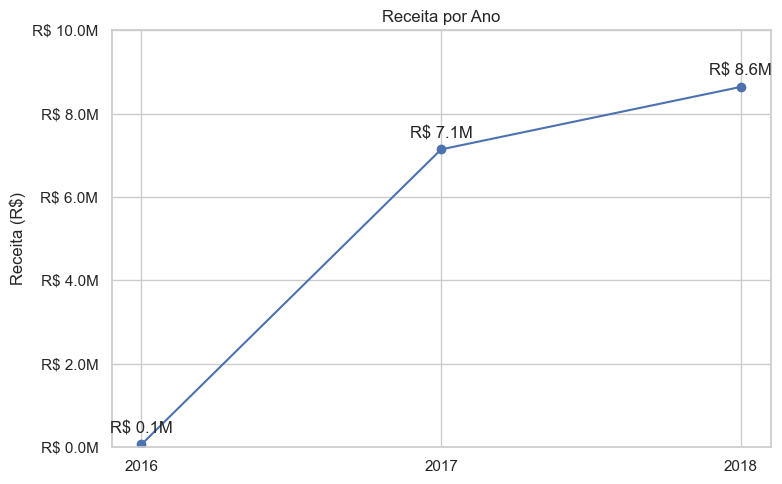

In [184]:

#revenue_year = df.groupby("year")["revenue"].sum()

#revenue_year.plot(kind="line", marker="o", title="Receita por Ano")
#revenue_year.plot(kind="bar", title="Receita por Ano")
#plt.ylabel("Receita (R$)")
#plt.show()

#Revenue_year trata-se da receita total por ano, calculada somando a receita de todos os pedidos entregues em cada ano. O gráfico de linha mostra a tendência da receita ao longo dos anos, 
# permitindo identificar se houve crescimento, queda ou estabilidade na receita anual da Olist.   


##NECESSITA FORMATAR O EIXO Y PARA MOEDA BRASILEIRA (R$) PARA MELHOR VISUALIZAÇÃO. E AJUSTA O EIXO X PARA MOSTRAR OS ANOS DE FORMA MAIS CLARA.



revenue_year = df.groupby("year")["revenue"].sum()

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    revenue_year.index.astype(str),  # eixo X como TEXTO (Ano)
    revenue_year.values,
    marker="o"
)

ax.set_title("Receita por Ano")
ax.set_ylabel("Receita (R$)")

# ✅ Formatter em milhões
formatter = FuncFormatter(lambda x, _: f"R$ {x/1e6:.1f}M")
ax.yaxis.set_major_formatter(formatter)

# ✅ Limite do eixo Y até 10.0M
ax.set_ylim(0, 10_000_000)

# ✅ Inserir valores nos pontos
for x, y in zip(revenue_year.index.astype(str), revenue_year.values):
    ax.annotate(
        formatter(y, None),
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.tight_layout()
plt.show()



# 3.1 Codigo melhorado para visualização

Segunda opção

In [185]:

# # Agregação
# revenue_year = df.groupby("year")["revenue"].sum()

# plt.figure(figsize=(10, 6))

# plt.plot(
#     revenue_year.index,
#     revenue_year.values / 1_000_000,  # em milhões
#     marker="o",
#     linewidth=3
# )

# plt.title("Receita por Ano", fontsize=14, fontweight="bold")
# plt.xlabel("Ano")
# plt.ylabel("Receita (R$ milhões)")
# plt.grid(axis="y", linestyle="--", alpha=0.5)
# plt.xticks(revenue_year.index.astype(int)) #garante que os anos sejam mostrados como inteiros
# plt.ylim(0,10) #ajusta o limite do eixo y para melhor visualização
# # Rótulos nos pontos
# for year, value in revenue_year.items():
#     plt.text(
#         year,
#         value / 1_000_000,
#         f"{value/1_000_000:,.2f}",
#         ha="center",
#         va="bottom",
#         fontsize=9
#     )

# plt.tight_layout()
# plt.show()


# 4.0 Visão Executiva - Receita por mes

Demonstra resultado por mês com escala de K Reais.
    foi filtrado para considerar menor ou igual a 2018-08-31, evitando demonstrar Queda no grafico devido a falta de dados os períodos à frente!!!

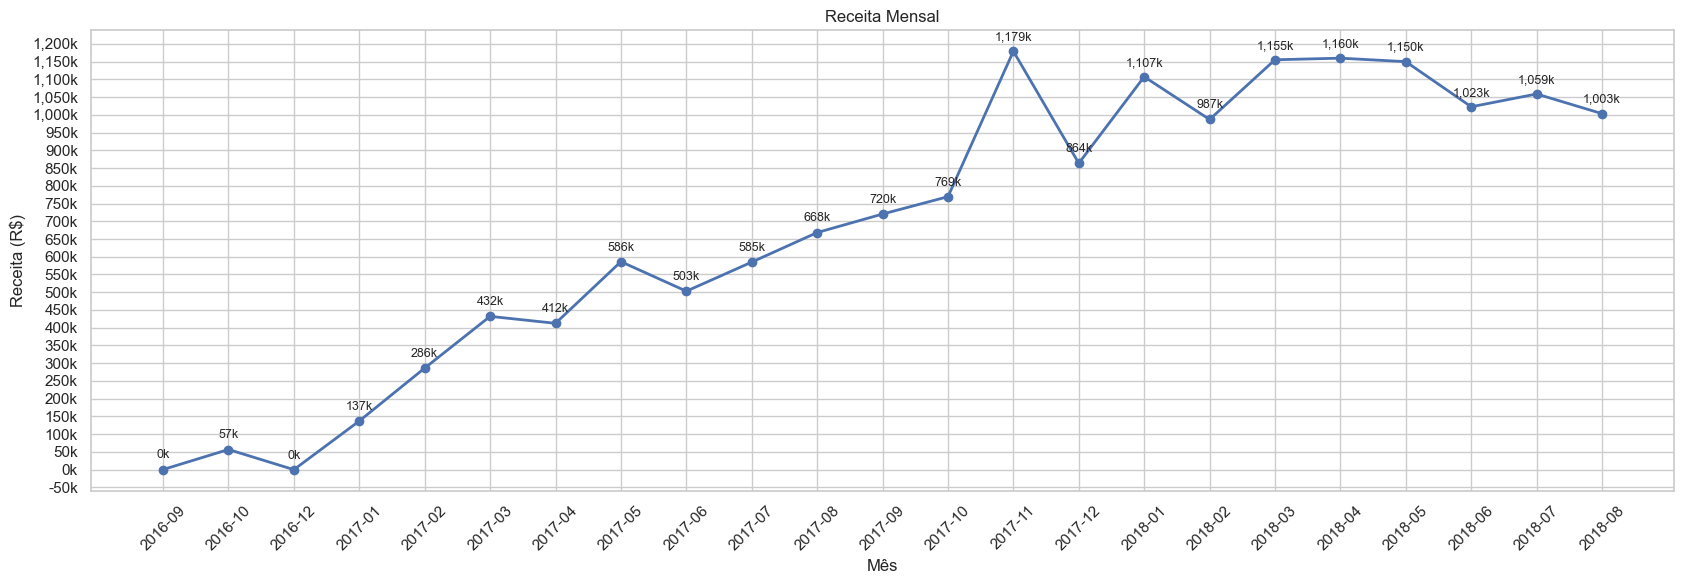

In [189]:
# import seaborn as sns
# import matplotlib.ticker as ticker
# revenue_month = df.groupby("month")["revenue"].sum().reset_index(name='valor_$') #reset_index() transformar em dataframe


# # ✅ Converte o índice para string no formato 2017-10(yyyy-mm)
# revenue_month.index = revenue_month.index.astype(str)

# axis = revenue_month.plot(x='month',y='valor_$',figsize=(17,6),grid=True,linewidth=2,marker='o')
# axis.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))



import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator
import pandas as pd

sns.set_theme(style="whitegrid")

# ✅ Garantir que month seja datetime
#df["month"] = pd.to_datetime(df["month"])

# ✅ Filtrar dados até 2018-08
df_filtered = df[df["month"] <= "2018-08-31"]

# Agregação
revenue_month = (
    df_filtered.groupby("month")["revenue"]
               .sum()
               .reset_index(name="valor_$")
)

# ✅ Converter mês para texto (yyyy-mm) apenas para o gráfico
revenue_month["month"] = revenue_month["month"].dt.strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(17, 6))

ax.plot(
    revenue_month["month"],
    revenue_month["valor_$"],
    linewidth=2,
    marker="o"
)

ax.set_title("Receita Mensal")
ax.set_ylabel("Receita (R$)")
ax.set_xlabel("Mês")

# ✅ Formatter eje Y em 'k'
formatter = FuncFormatter(lambda x, _: f"{x/1000:,.0f}k")
ax.yaxis.set_major_formatter(formatter)
ax.yaxis.set_major_locator(MultipleLocator(50000))

# ✅ Valores dentro do gráfico
for x, y in zip(revenue_month["month"], revenue_month["valor_$"]):
    ax.annotate(
        formatter(y, None),
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9
    )

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




# 5.0 Visão Executiva (1) - Receita por UF

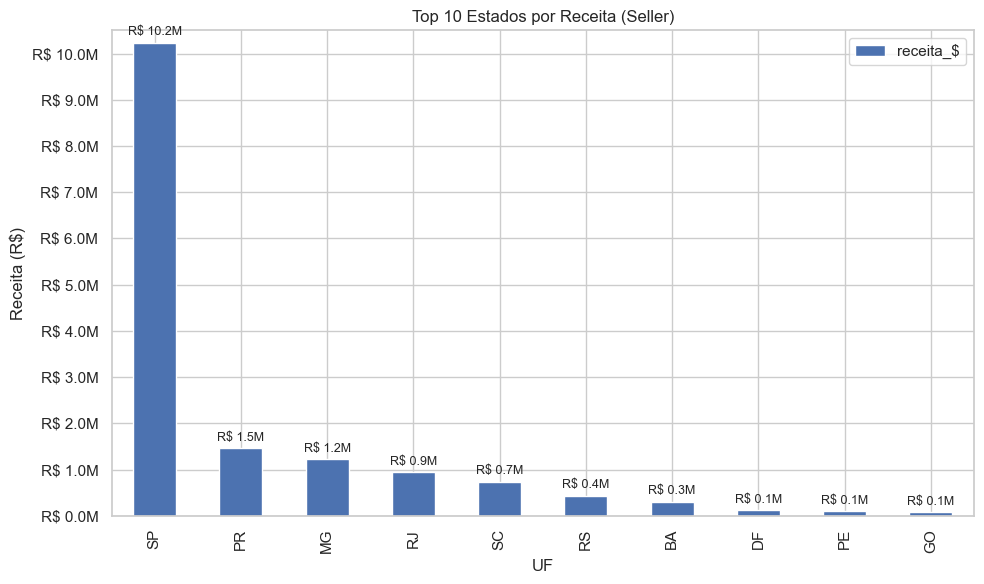

In [223]:


import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator

# ✅ Top 10 UFs por receita
revenue_region = (
    df.groupby("seller_state")["revenue"]
      .sum()
      .reset_index(name="receita_$")
      .sort_values(by="receita_$", ascending=False)
      .head(10)
)

fig, ax = plt.subplots(figsize=(10, 6))

# Gráfico de barras
revenue_region.plot(
    x="seller_state",
    y="receita_$",
    kind="bar",
    ax=ax,
    title="Top 10 Estados por Receita (Seller)"
)

ax.set_ylabel("Receita (R$)")
ax.set_xlabel("UF")

# ✅ Formatter em milhões (M)
formatter = FuncFormatter(lambda x, _: f"R$ {x/1e6:.1f}M")
ax.yaxis.set_major_formatter(formatter)

# ✅ Escala do eixo Y até 10.5M
ax.set_ylim(0, 10_500_000)

# (Opcional, mas melhora leitura)
ax.yaxis.set_major_locator(MultipleLocator(1_000_000))

# ✅ Valores nas barras (container)
for container in ax.containers:
    labels = [formatter(v, None) for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, fontsize=9)

plt.tight_layout()
plt.show()




# 5.1 Visão Executiva (2) - Receita por UF

In [191]:
pip install geopandas

   ---------------------------------------- 0.0/23.6 MB ? eta -:--:--
   --- ------------------------------------ 1.8/23.6 MB 9.5 MB/s eta 0:00:03
   ----- ---------------------------------- 3.4/23.6 MB 9.0 MB/s eta 0:00:03
   -------- ------------------------------- 5.2/23.6 MB 9.0 MB/s eta 0:00:03
   ------------ --------------------------- 7.3/23.6 MB 9.1 MB/s eta 0:00:02
   ---------------- ----------------------- 9.4/23.6 MB 9.2 MB/s eta 0:00:02
   ------------------- -------------------- 11.3/23.6 MB 9.3 MB/s eta 0:00:02
   ---------------------- ----------------- 13.4/23.6 MB 9.3 MB/s eta 0:00:02
   -------------------------- ------------- 15.5/23.6 MB 9.4 MB/s eta 0:00:01
   ----------------------------- ---------- 17.3/23.6 MB 9.3 MB/s eta 0:00:01
   -------------------------------- ------- 18.9/23.6 MB 9.3 MB/s eta 0:00:01
   ----------------------------------- ---- 20.7/23.6 MB 9.2 MB/s eta 0:00:01
   -------------------------------------- - 22.8/23.6 MB 9.3 MB/s eta 0:00:01

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [206]:

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker


In [207]:
#Carregando o Mapa do Brasil (GeoJSON)

br_states = gpd.read_file(
    "https://raw.githubusercontent.com/codeforamerica/click_that_hood/master/public/data/brazil-states.geojson"
)


In [208]:

# Padronizando os nomes
br_states = br_states.rename(columns={"sigla": "seller_state"})


In [209]:

map_df = br_states.merge(
    revenue_region,
    on="seller_state",
    how="left"
)


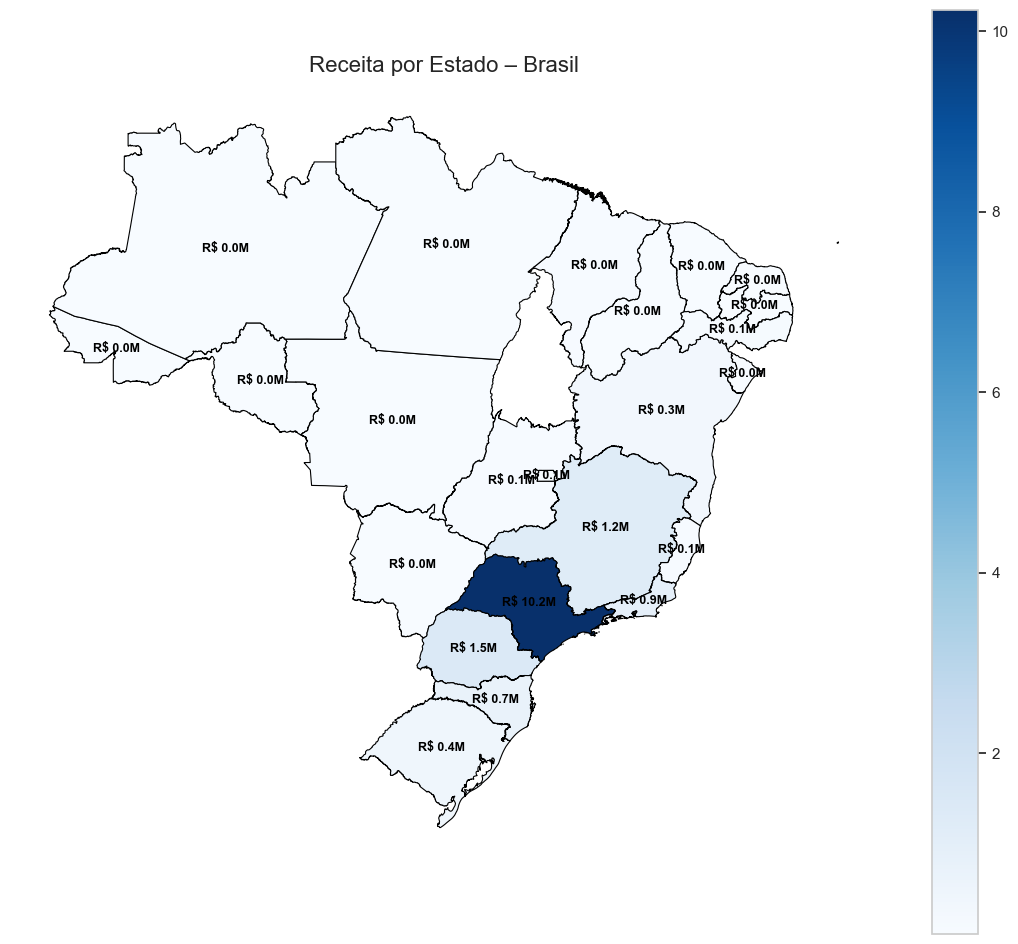

In [217]:
fig, ax = plt.subplots(1, 1, figsize=(14, 12))
map_df["receita_M"] = map_df["receita_$"] / 1_000_000


map_df["label"] = map_df["receita_M"].apply(
    lambda x: f"R$ {x:.1f}M" if x > 0 else ""
)



# Mapa base
map_df.plot(
    column="receita_M",
    cmap="Blues",
    linewidth=0.8,
    edgecolor="black",
    legend=True,
    ax=ax
)

ax.set_title("Receita por Estado – Brasil", fontsize=16)
ax.axis("off")


# # ✅ Formatar legenda em milhões
# leg = ax.get_legend()
# if leg:
#     for t in leg.get_texts():
#         t.set_text(f"R$ {int(float(t.get_text())/1_000_000)}M")



for _, row in map_df.iterrows():
    if row["receita_M"] > 0:
        # Centróide do estado
        x = row.geometry.centroid.x
        y = row.geometry.centroid.y

        ax.annotate(
            text=row["label"],
            xy=(x, y),
            ha="center",
            va="center",
            fontsize=9,
            color="black",
            fontweight="bold"
        )


plt.show()


# 6.0 Ticket Médio
 (ticket medio = Receita / numero de pedidos unicos)

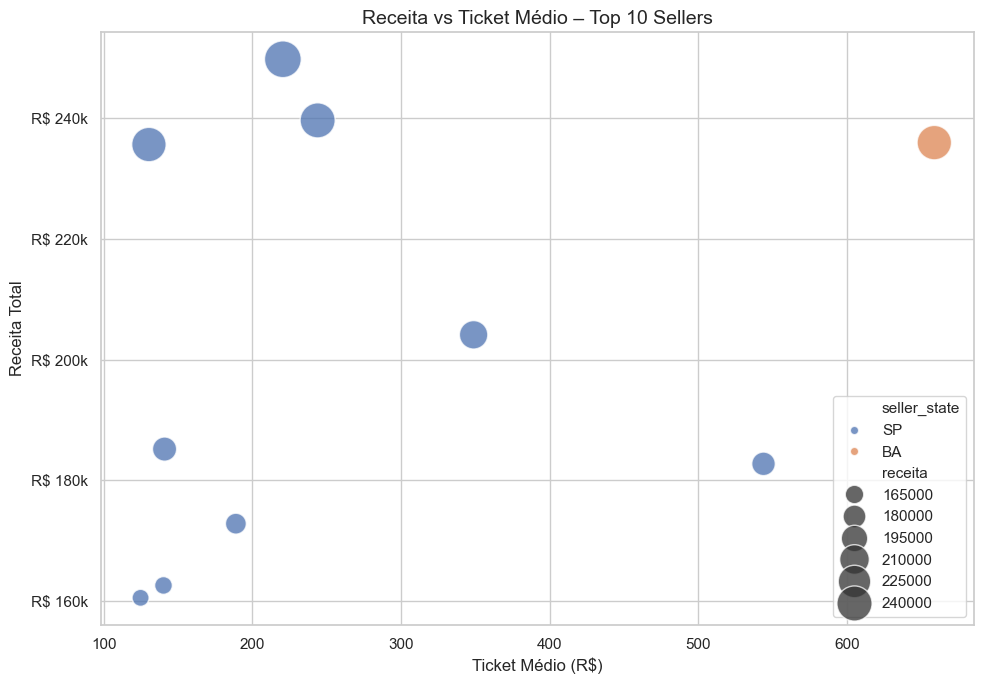

In [242]:



import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid")

# ✅ Agregação por Seller
seller_metrics = (
    df.groupby(["seller_id", "seller_state"])
      .agg(
          receita=("revenue", "sum"),
          pedidos=("order_id", "nunique")
      )
      .reset_index()
)

# ✅ Ticket médio
seller_metrics["ticket_medio"] = (
    seller_metrics["receita"] / seller_metrics["pedidos"]
)

# ✅ Top 10 sellers por receita
top_10_sellers = (
    seller_metrics
    .sort_values("receita", ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(
    data=top_10_sellers,
    x="ticket_medio",
    y="receita",
    hue="seller_state",
    size="receita",
    sizes=(150, 700),
    alpha=0.75,
    ax=ax
)

ax.set_title("Receita vs Ticket Médio – Top 10 Sellers", fontsize=14)
ax.set_xlabel("Ticket Médio (R$)")
ax.set_ylabel("Receita Total")

# ✅ Formatter eixo Y em K reais
formatter_k = FuncFormatter(lambda y, _: f"R$ {y/1000:,.0f}k")
ax.yaxis.set_major_formatter(formatter_k)

plt.tight_layout()
plt.show()



# 7.0 Top 15 - Receita por Categoria

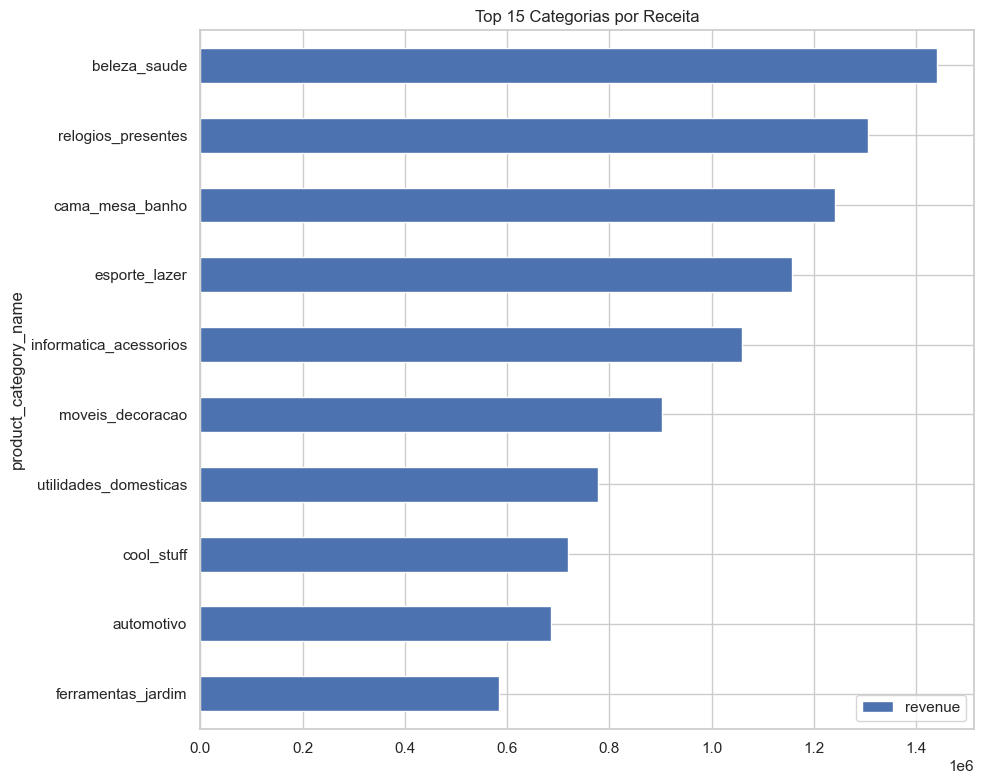

In [256]:
top_cat = df_cat_region.groupby('product_category_name', as_index=False)['revenue'].sum()
top_cat = top_cat.sort_values('revenue', ascending=False).head(10)

ax = top_cat.plot(
    kind='barh',
    x='product_category_name',
    y='revenue',
    figsize=(10, 8),
    title='Top 15 Categorias por Receita'
)

ax.invert_yaxis()
plt.tight_layout()
plt.show()

# 7.1 Top 5 Receita por Categoria / Ano

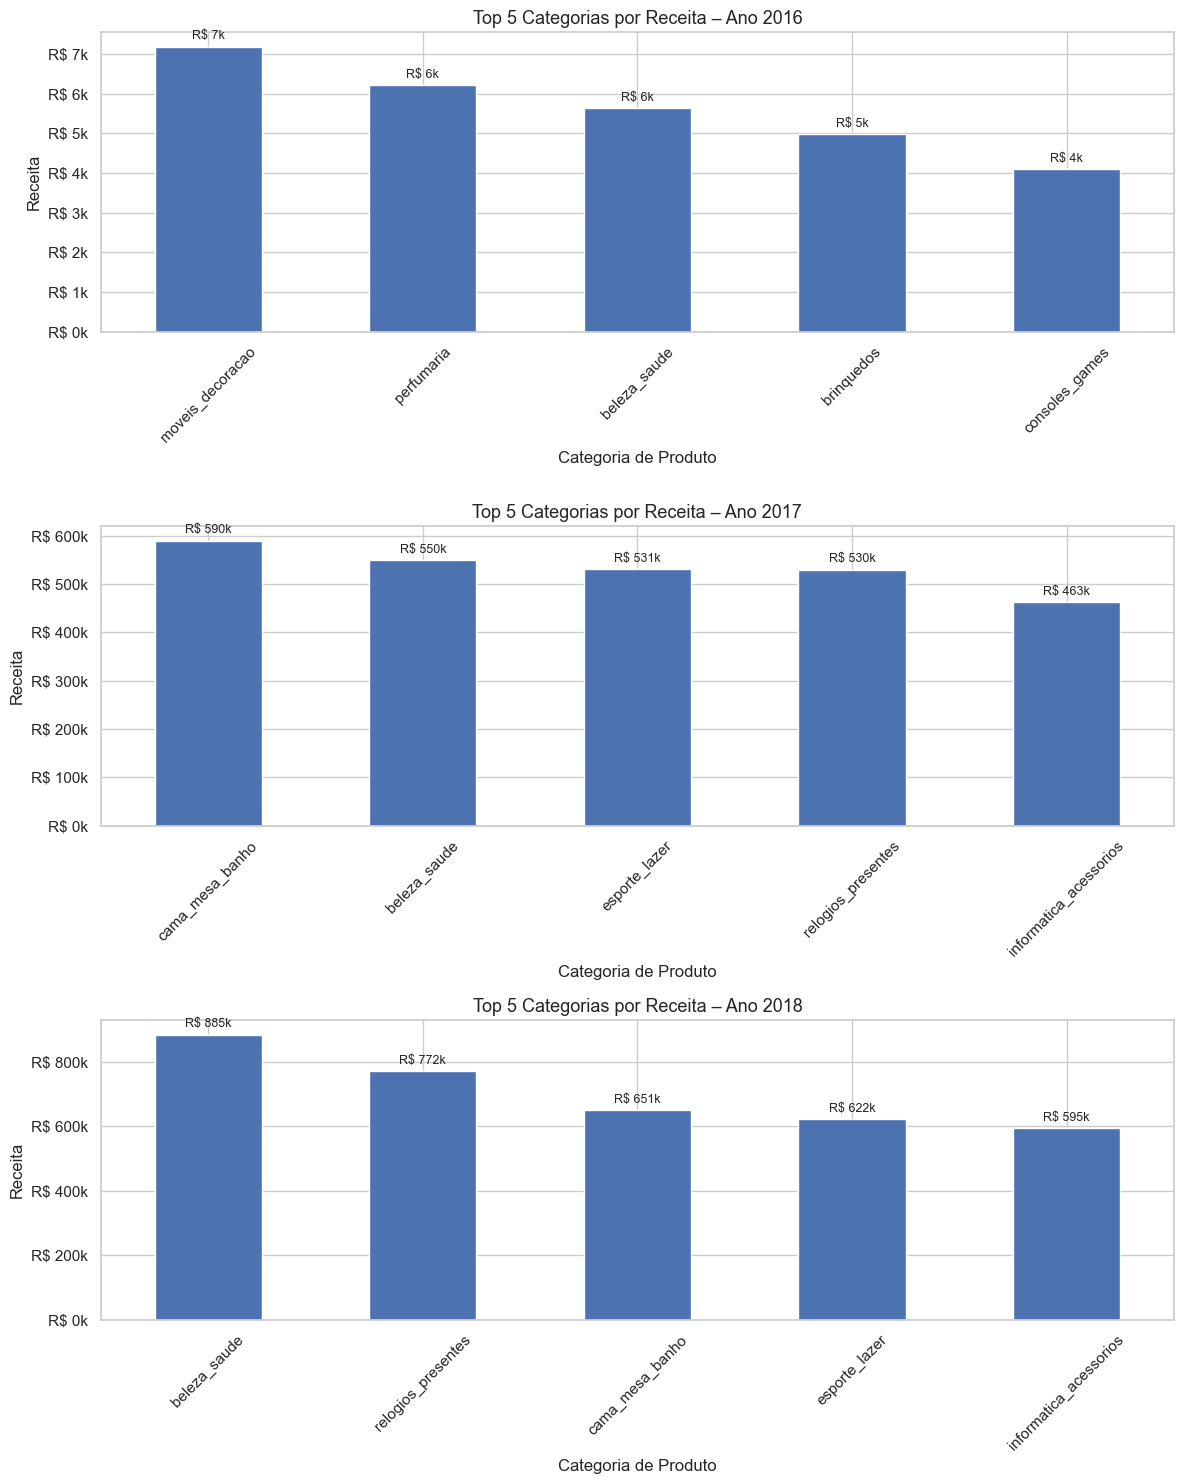

In [262]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd

# Garantir year como int
df["year"] = df["year"].astype(int)

# Receita por Ano + Categoria
revenue_cat_year = (
    df.groupby(["year", "product_category_name"])["revenue"]
      .sum()
      .reset_index(name="receita")
)

#formatter_k = FuncFormatter(lambda x, _: f"R$ {x/1000:,.0f}k")

years = sorted(revenue_cat_year["year"].unique())

fig, axes = plt.subplots(
    nrows=len(years),
    ncols=1,
    figsize=(12, 5 * len(years)),
    sharex=False
)

# Garante que axes seja iterável quando houver apenas 1 ano
if len(years) == 1:
    axes = [axes]

for ax, year in zip(axes, years):

    plot_df = (
        revenue_cat_year[revenue_cat_year["year"] == year]
        .sort_values("receita", ascending=False)
        .head(5)
    )

    plot_df.plot(
        x="product_category_name",
        y="receita",
        kind="bar",
        ax=ax,
        legend=False
    )

    ax.set_title(f"Top 5 Categorias por Receita – Ano {year}", fontsize=13)
    ax.set_ylabel("Receita")
    ax.set_xlabel("Categoria de Produto")

    # ✅ Eixo Y em K reais
    ax.yaxis.set_major_formatter(formatter_k)

    # ✅ Valores nas barras
    for container in ax.containers:
        labels = [formatter_k(v, None) for v in container.datavalues]
        ax.bar_label(container, labels=labels, padding=3, fontsize=9)

    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()



# Info adicionais

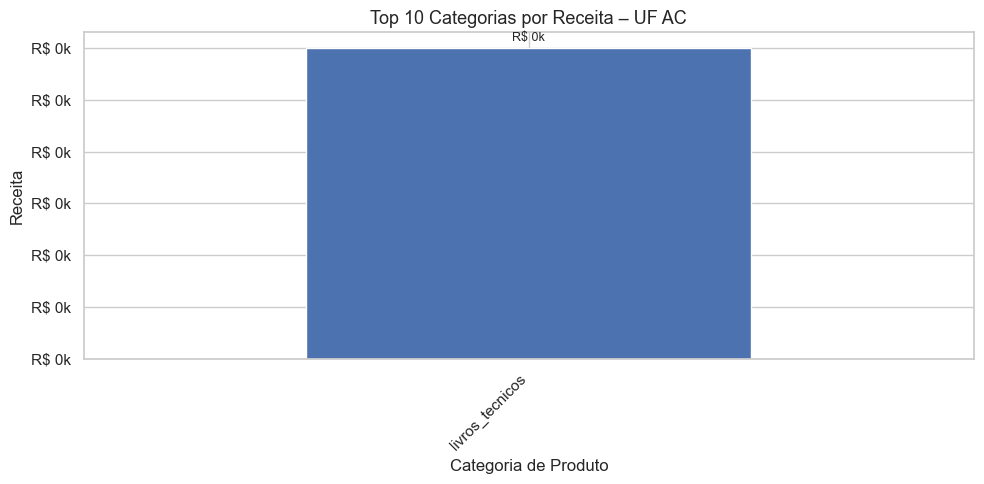

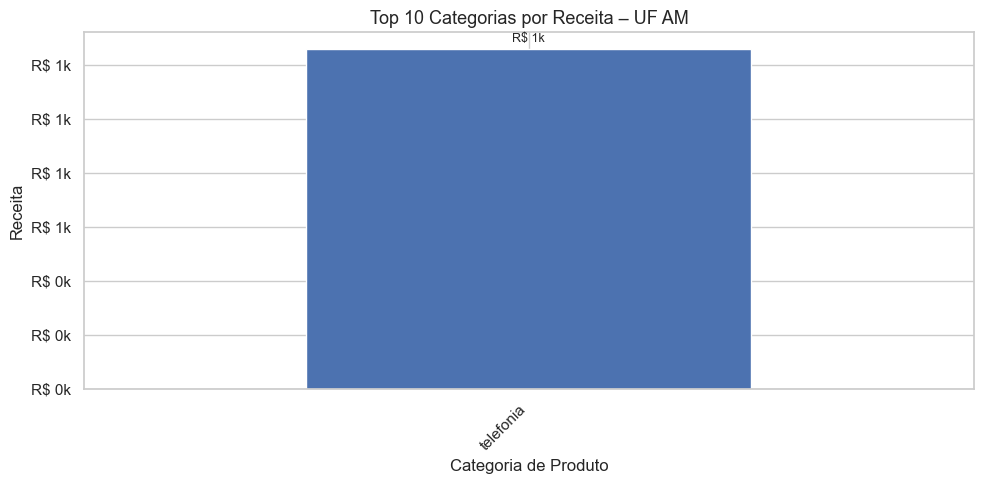

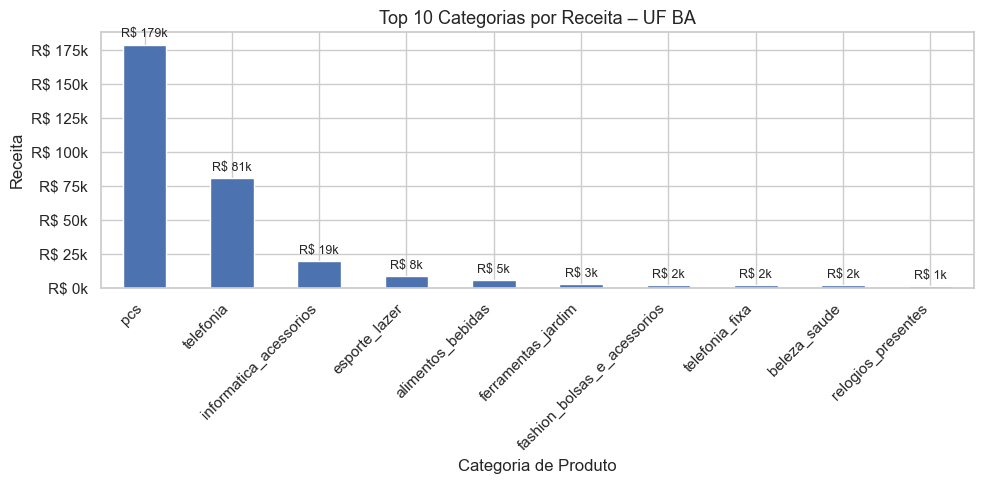

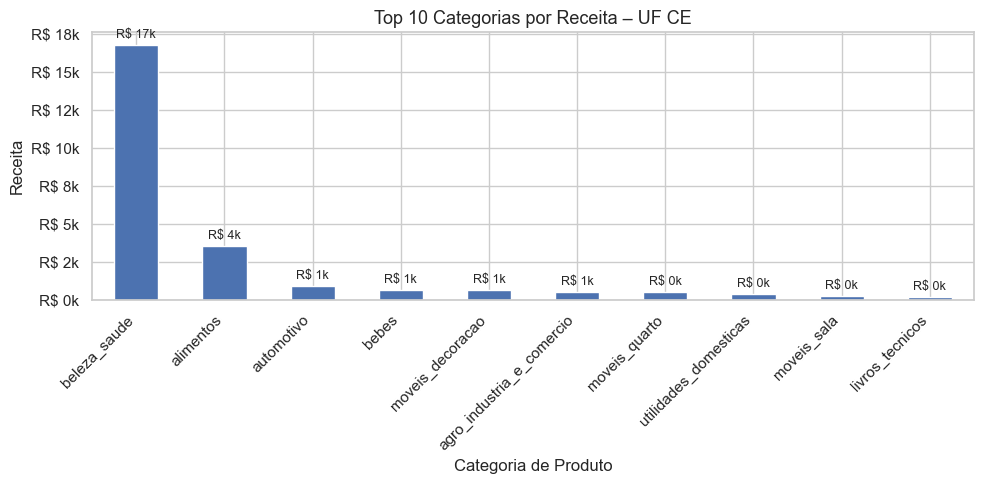

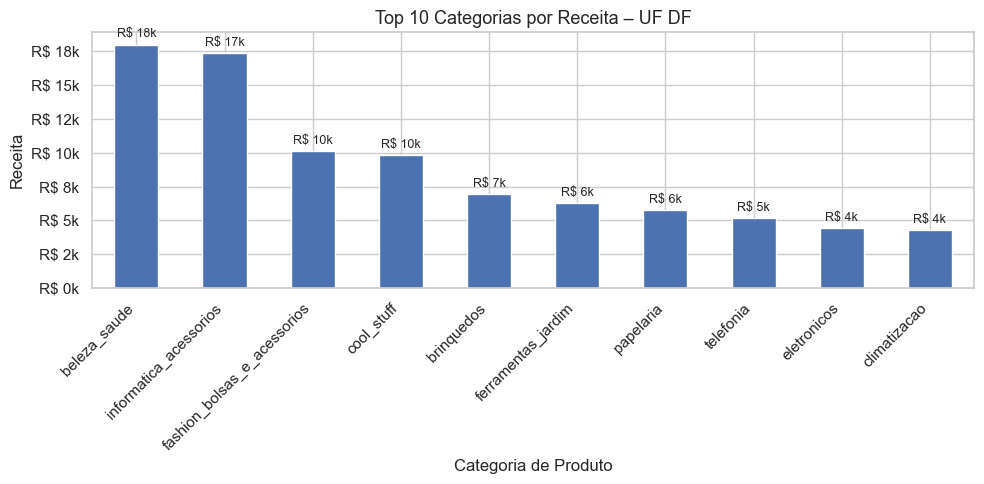

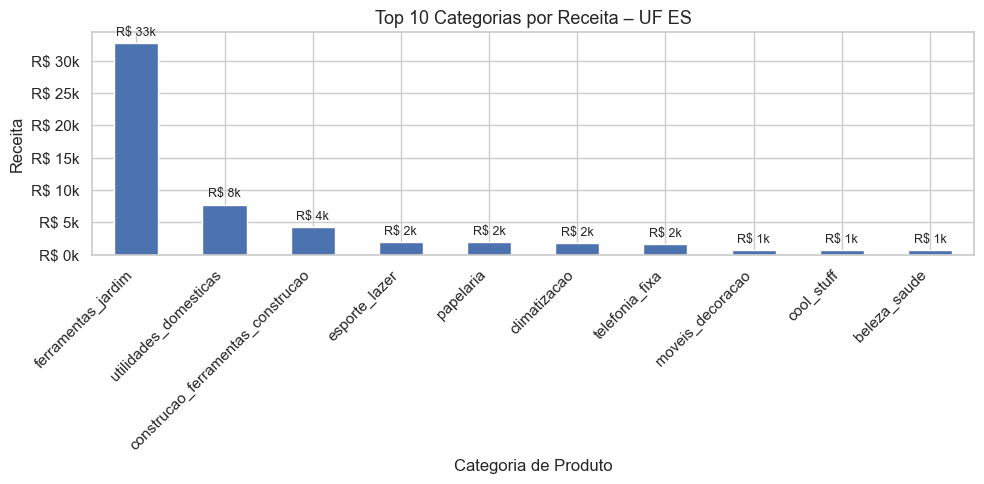

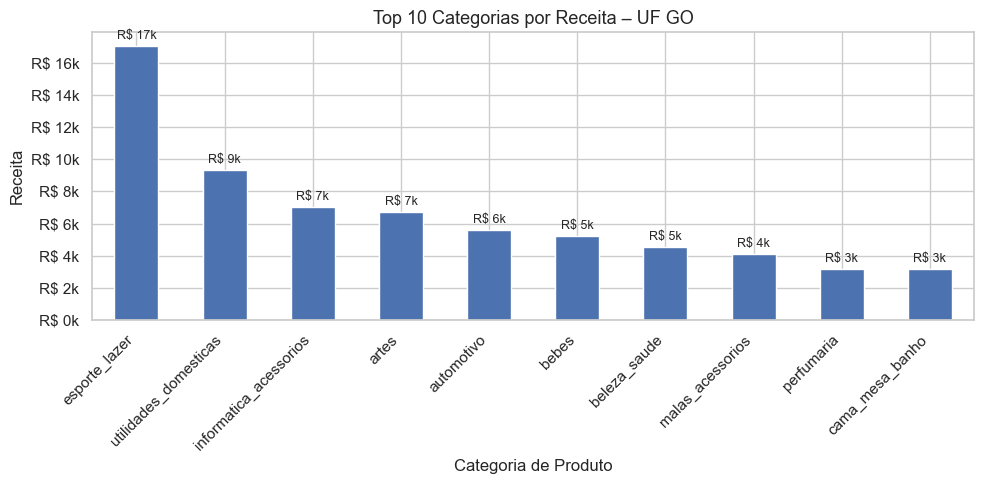

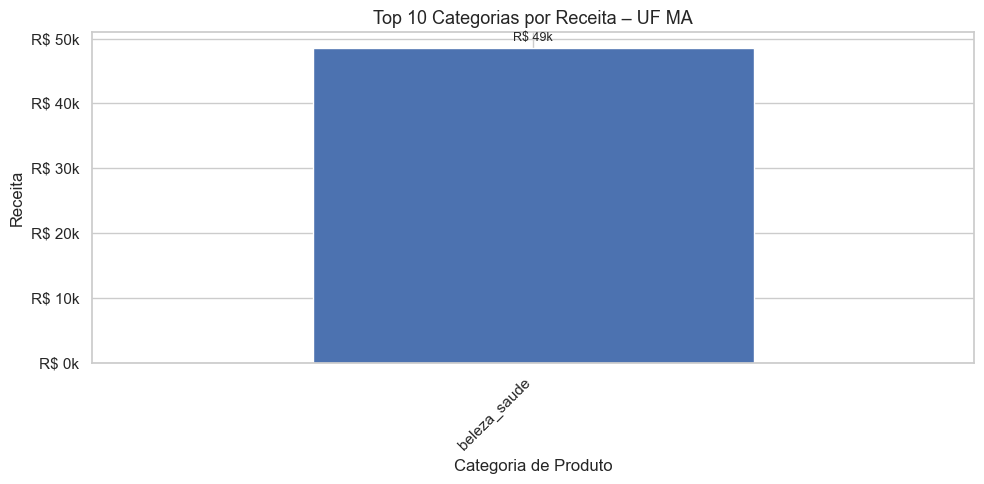

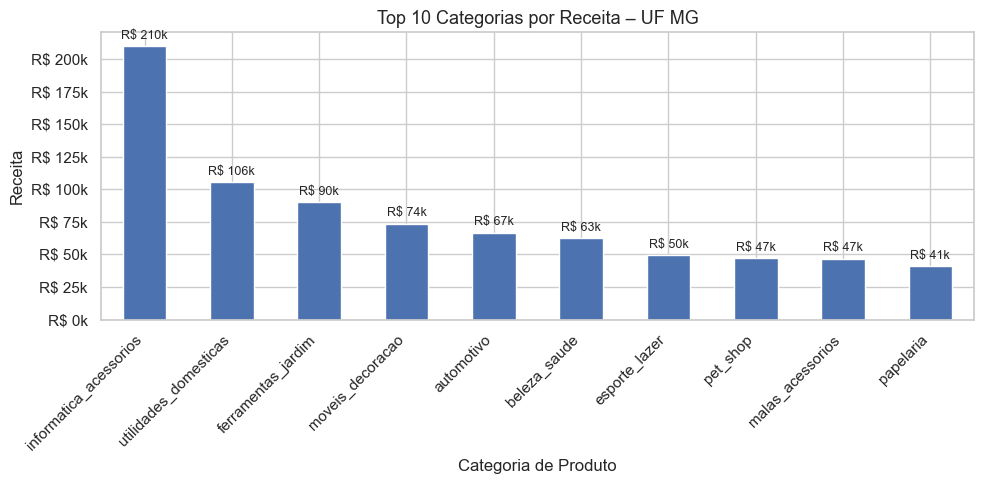

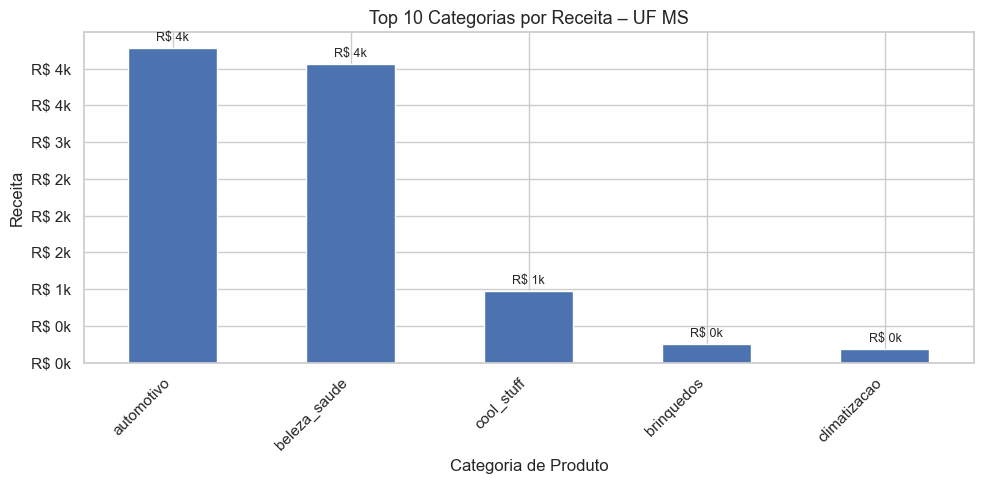

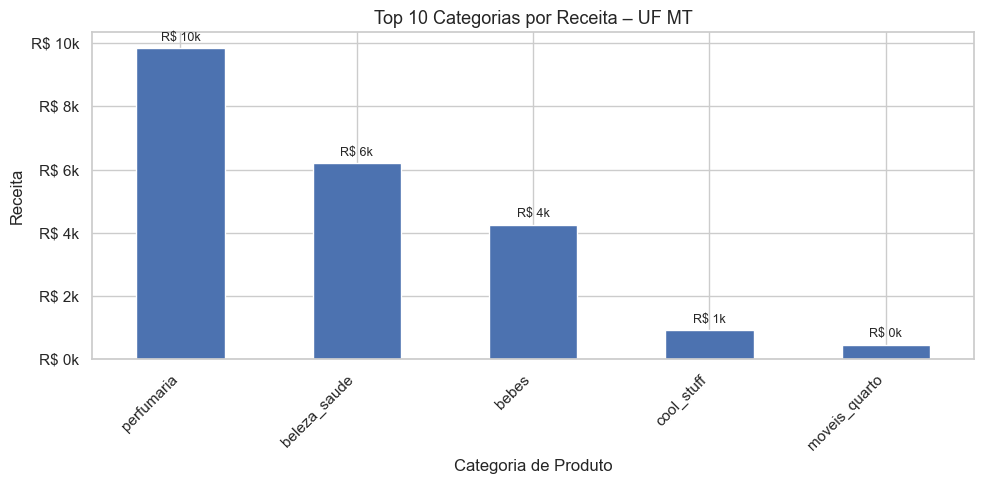

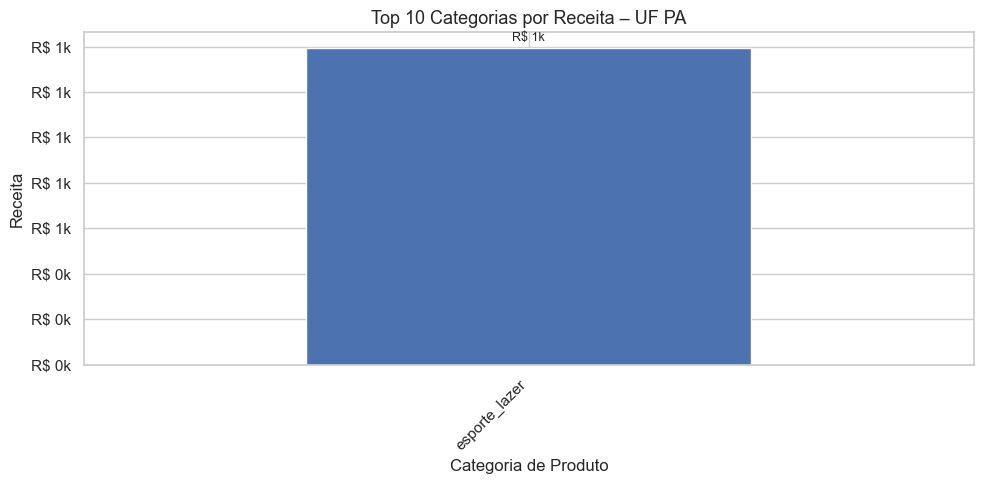

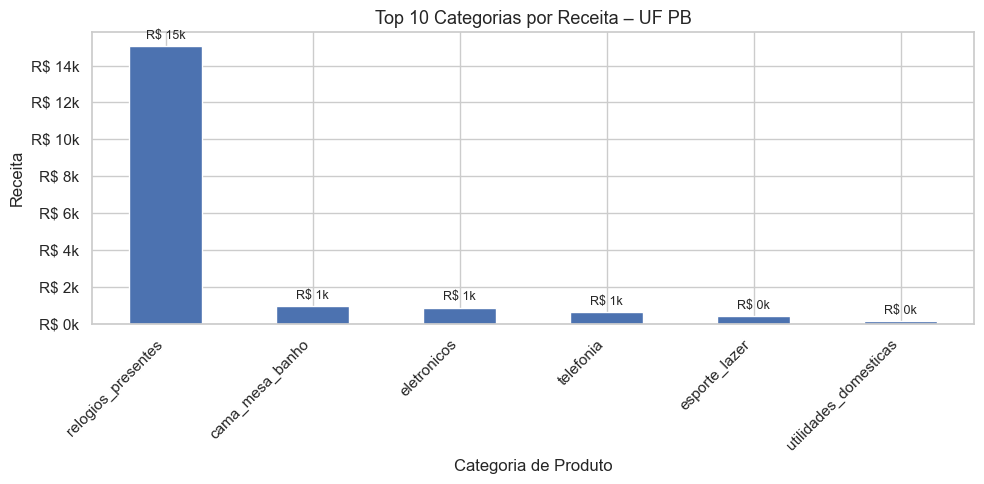

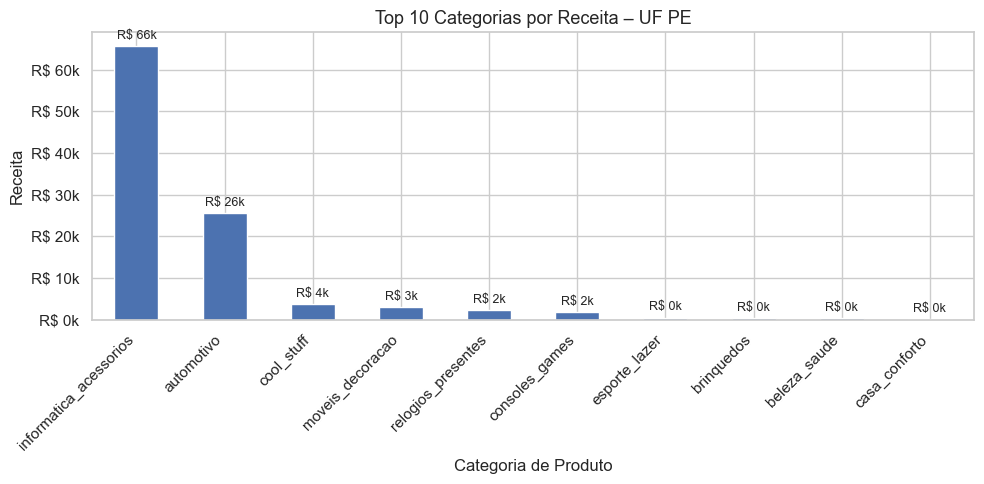

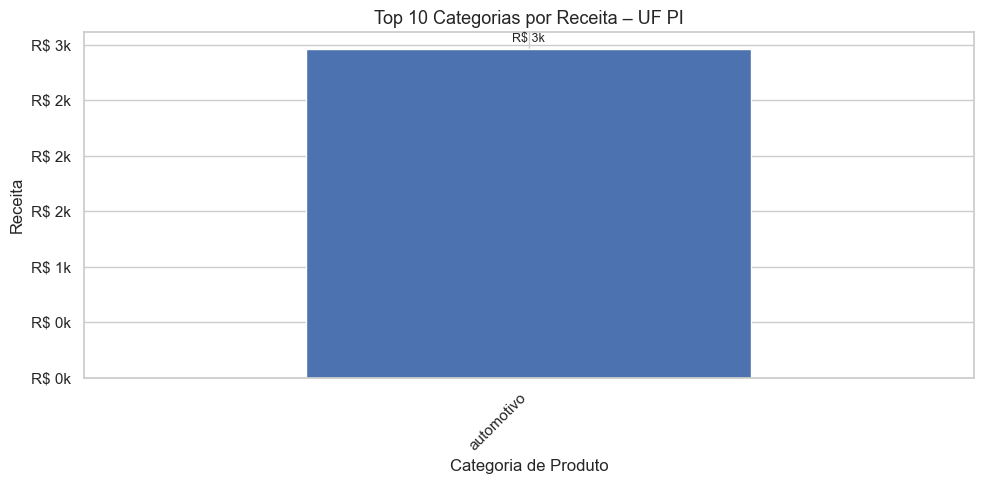

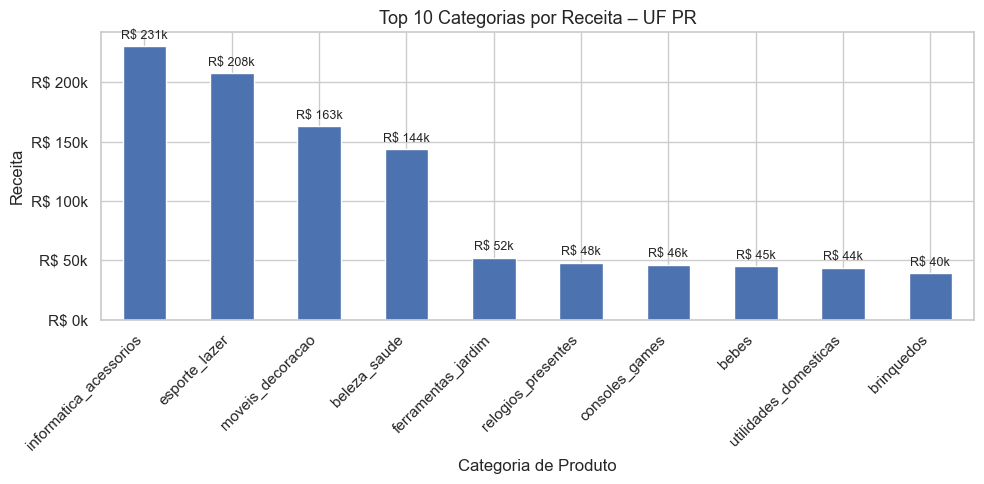

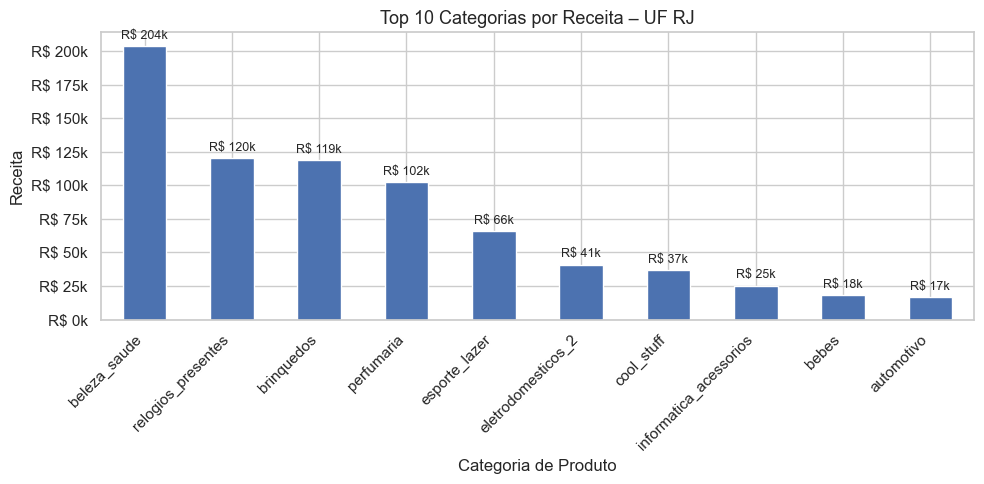

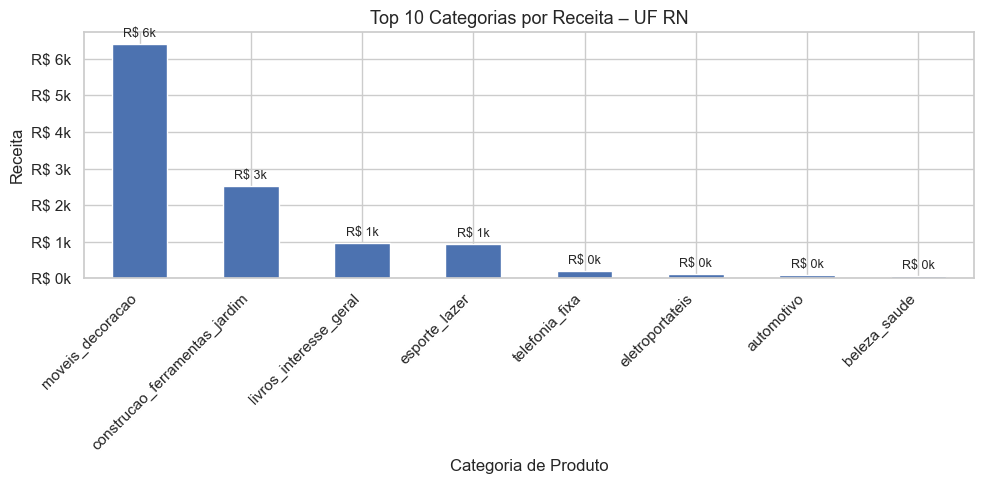

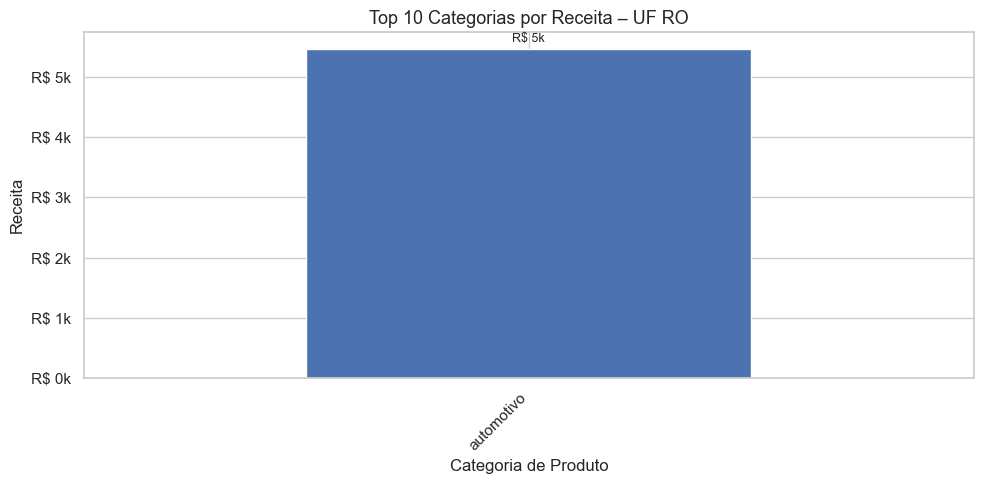

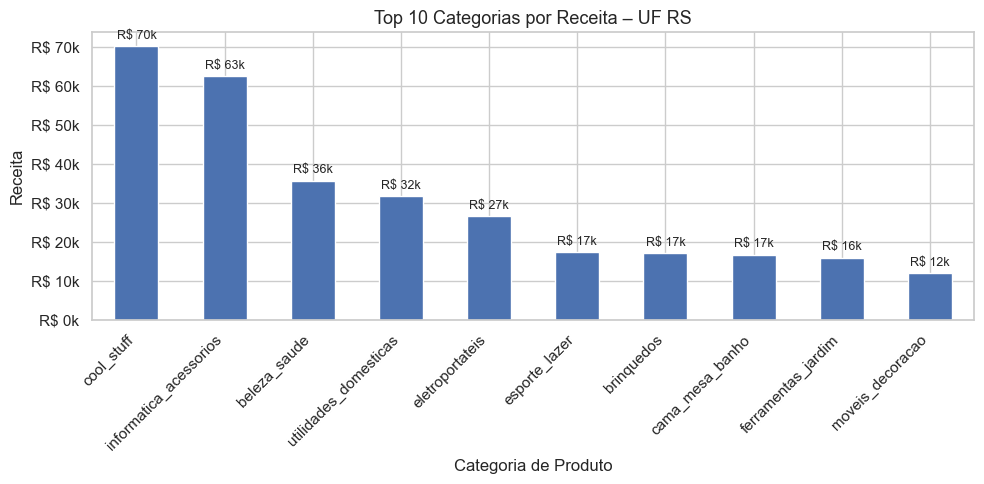

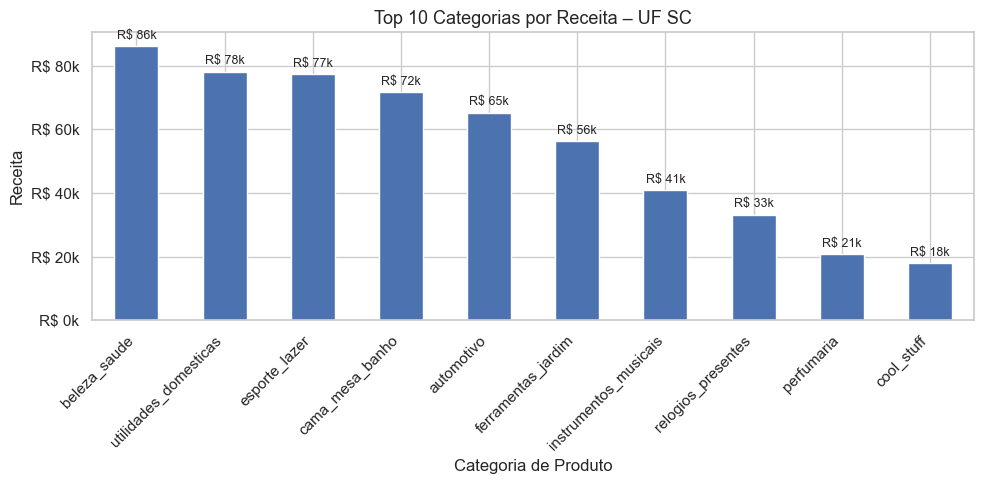

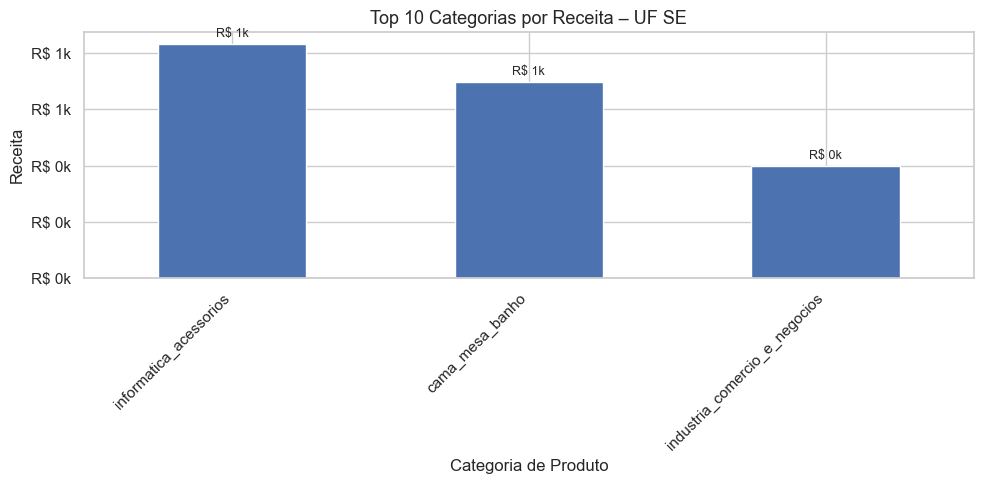

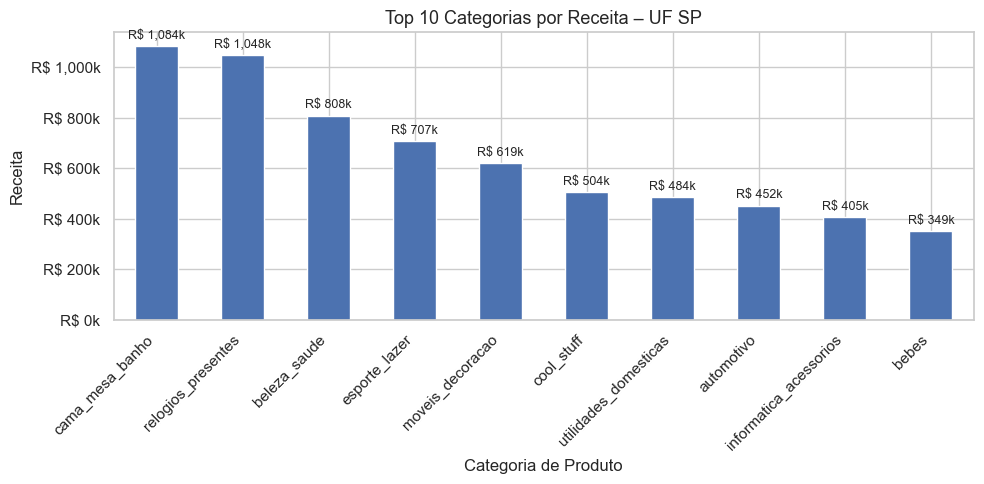

In [ ]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Agregar receita por UF + categoria
revenue_cat_uf = (
    df.groupby(["seller_state", "product_category_name"])["revenue"]
      .sum()
      .reset_index(name="receita")
)

formatter_k = FuncFormatter(lambda x, _: f"R$ {x/1000:,.0f}k")


ufs = revenue_cat_uf["seller_state"].unique()

for uf in ufs:

    # ✅ Top 10 categorias da UF
    plot_df = (
        revenue_cat_uf[revenue_cat_uf["seller_state"] == uf]
        .sort_values("receita", ascending=False)
        .head(10)
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    plot_df.plot(
        x="product_category_name",
        y="receita",
        kind="bar",
        ax=ax,
        legend=False
    )

    ax.set_title(f"Top 10 Categorias por Receita – UF {uf}", fontsize=13)
    ax.set_xlabel("Categoria de Produto")
    ax.set_ylabel("Receita")

    # ✅ Eixo Y em K reais
    ax.yaxis.set_major_formatter(formatter_k)

    # ✅ Valores nas barras (container)
    for container in ax.containers:
        labels = [formatter_k(v, None) for v in container.datavalues]
        ax.bar_label(container, labels=labels, padding=3, fontsize=9)

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

